In [3]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Load dataset
data = pd.read_csv("winequality-red.csv")
data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [6]:
print("Dataset size = ",data.shape)
print("Columns =",data.columns)
print("Missing Values",data.isnull().sum())

#features and target
X = data.drop('quality', axis=1) #feauture 11 col
y = data['quality'] #target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Dataset size =  (1599, 12)
Columns = Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')
Missing Values fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [5]:
#apply PCA

In [7]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Variance Ratio =",pca.explained_variance_ratio_)
print("Total Variance Explained =",sum(pca.explained_variance_ratio_))

Variance Ratio = [0.28173931 0.1750827 ]
Total Variance Explained = 0.45682201184294047


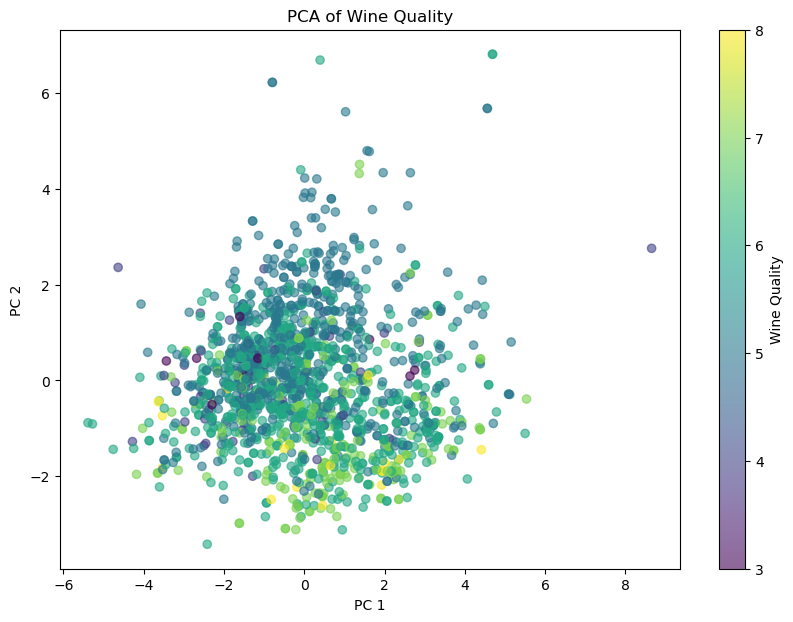

In [10]:
plt.figure(figsize=(10,7))
scatter = plt.scatter(
    X_pca[:, 0],   # First Principal Component
    X_pca[:, 1],   # Second Principal Component
    c=y,
    cmap='viridis',
    alpha=0.6
)

plt.colorbar(scatter, label="Wine Quality")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.title("PCA of Wine Quality")
plt.show()

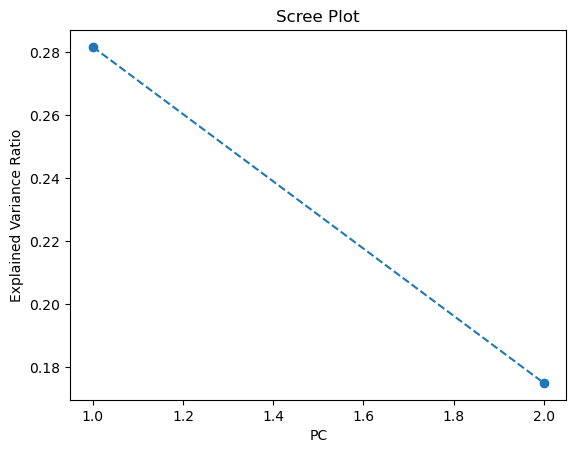

Accuracy: 0.5375
Original Accuracy = 0.65


In [14]:
# Scree Plot -> Explained Variance
plt.plot(range(1,3), pca.explained_variance_ratio_, marker="o", linestyle="--")
plt.xlabel("PC")
plt.ylabel("Explained Variance Ratio")
plt.title("Scree Plot")
plt.show()

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X_pca, y, test_size=0.2, random_state=42
)

# Train Random Forest Classifier
clf = RandomForestClassifier(random_state=42)
clf.fit(X_train, y_train)

# Prediction
y_pred = clf.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

#compare with original features
# Train-test split on original scaled data
X_train_o, X_test_o, y_train_o, y_test_o = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

# Train Random Forest
clf = RandomForestClassifier(random_state=42)
clf.fit(X_train_o, y_train_o)

# Prediction
y_pred_o = clf.predict(X_test_o)

# Accuracy
accuracy_o = accuracy_score(y_test_o, y_pred_o)
print("Original Accuracy =", accuracy_o)
